In [ ]:
# ============================================================
# Chargement des données locales
# ============================================================
# Ce notebook a été adapté pour fonctionner en local
# (remplace le chargement depuis Google Sheets)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.cluster.hierarchy import dendrogram, linkage
from wordcloud import WordCloud

# Charger le dataset nettoyé
df = pd.read_csv("../data/processed/reviews_clean.csv")

# Afficher un aperçu
print(f"Dataset chargé : {df.shape[0]} avis, {df.shape[1]} colonnes")
print(f"Colonnes : {df.columns.tolist()}")
df.sample(5)

In [ ]:
# 5 exemples aléatoires par cluster
for c in sorted(df["cluster"].unique()):
    print(f"\n===== CLUSTER {c} =====")
    display(df[df["cluster"] == c].sample(5, random_state=42))



===== CLUSTER 0 =====


,review_text,title,company,category,source,datetime,category_slug,product_slug,char_len,text_clean_base,text_clean,rating,cluster
19393,Super impression et qualité des sacs en coton....,Super impression et qualité des sacs en…,,Shopping & mode,scraping_2025_batch,2020-01-21T10:11:22.000Z,shopping_fashion,www.sacpub.com,60,super impression et qualité des sacs en coton ...,super impression qualité sacs coton recommande,5,0
20024,Perdieme est une super marque alliant confort ...,Confort et style !,,Shopping & mode,scraping_2025_batch,2024-07-17T14:15:18.000Z,shopping_fashion,perdieme.com,82,perdieme est une super marque alliant confort ...,perdieme super marque alliant confort style éq...,5,0
4565,Je suis trop contente de mes bijoux commandés ...,Je suis trop contente de mes bijoux…,,Shopping & mode,scraping_2025_batch,2024-11-06T18:30:46.000Z,shopping_fashion,www.annavelazia.com,66,je suis trop contente de mes bijoux commandés ...,contente bijoux commandés jolies,5,0
7297,"Cliente depuis plusieurs années, je suis plein...",Parfait,,Shopping & mode,scraping_2025_batch,2025-08-14T13:22:24.000Z,shopping_fashion,www.touteslespoitrines.com,141,cliente depuis plusieurs années je suis pleine...,cliente plusieurs années pleinement satisfaite...,5,0
29336,Le SAV de la compagnie est très réactif et agr...,La livraison a été lamentable,,Shopping & mode,scraping_2025_batch,2025-02-21T11:50:49.000Z,shopping_fashion,b-outdoors.com,314,le sav de la compagnie est très réactif et agr...,sav compagnie réactif agréable livraison lamen...,4,0



===== CLUSTER 1 =====


,review_text,title,company,category,source,datetime,category_slug,product_slug,char_len,text_clean_base,text_clean,rating,cluster
4527,"Service client très réactif, livraison avec re...",Parfait!!!,,Shopping & mode,scraping_2025_batch,2022-02-13T16:28:19.000Z,shopping_fashion,ateliers-auguste.fr,111,service client très réactif livraison avec rem...,service client réactif livraison remise signat...,5,1
29865,Commande depuis longtemps et toujours aussi sa...,Satisfaction,,Shopping & mode,scraping_2025_batch,2025-07-08T09:24:03.000Z,shopping_fashion,maisononado.com,88,commande depuis longtemps et toujours aussi sa...,commande longtemps satisfaite bon produit bonn...,5,1
24617,Sac reçu très rapidement et de très bonne qual...,Très satisfaite,,Shopping & mode,scraping_2025_batch,2025-08-26T06:05:33.000Z,shopping_fashion,www.mesbagages.com,50,sac reçu très rapidement et de très bonne qualité,sac reçu bonne qualité,5,1
15184,Produits de qualité que je recommande.,Produits de qualité que je recommande.,,Shopping & mode,scraping_2025_batch,2025-05-11T21:14:07.000Z,shopping_fashion,chaussettes-bambou.fr,38,produits de qualité que je recommande,produits qualité recommande,5,1
29981,Magnifique bijoux de très bonne qualité. Le pa...,Sublime !,,Shopping & mode,scraping_2025_batch,2020-12-03T18:31:08.000Z,shopping_fashion,enjoyceshop.com,104,magnifique bijoux de très bonne qualité le pac...,magnifique bijoux bonne qualité packaging joli...,5,1



===== CLUSTER 2 =====


,review_text,title,company,category,source,datetime,category_slug,product_slug,char_len,text_clean_base,text_clean,rating,cluster
6333,"commande facile, livraison rapide, colis en pa...",commande facile,,Shopping & mode,scraping_2025_batch,2025-07-26T20:18:17.000Z,shopping_fashion,ekosport.fr,61,commande facile livraison rapide colis en parf...,commande facile livraison rapide colis parfait...,5,2
5828,Délais de livraison respectés et produits tota...,Délais de livraison respectés et…,,Shopping & mode,scraping_2025_batch,2024-09-02T08:26:51.000Z,shopping_fashion,www.visagechaussettes.fr,104,délais de livraison respectés et produits tota...,délais livraison respectés produits totalement...,5,2
22058,Bon produit avec livraison rapide. Le suivi du...,Bon produit avec livraison rapide,,Shopping & mode,scraping_2025_batch,2025-07-22T07:19:26.000Z,shopping_fashion,www.tendancechaussures.com,64,bon produit avec livraison rapide le suivi du ...,bon produit livraison rapide suivi colis parfait,5,2
4827,Parfait!! Hyper réactive travail parfait Je su...,Parfait!,,Shopping & mode,scraping_2025_batch,2022-11-03T11:50:40.000Z,shopping_fashion,bcbgbabycraftbabygood.fr,151,parfait hyper réactive travail parfait je suis...,parfait hyper réactive travail parfait content...,5,2
4958,"Parfait , magnifique bijoux. Envoi rapide et s...",Parfait,,Shopping & mode,scraping_2025_batch,2024-12-26T16:17:09.000Z,shopping_fashion,gautrot.com,52,parfait magnifique bijoux envoi rapide et soigné,parfait magnifique bijoux envoi rapide soigné,5,2



===== CLUSTER 3 =====


,review_text,title,company,category,source,datetime,category_slug,product_slug,char_len,text_clean_base,text_clean,rating,cluster
12306,N’achetez surtout pas sur ce site ils vendent ...,N’achetez surtout pas sur ce site ils…,,Shopping & mode,scraping_2025_batch,2023-01-08T00:00:52.000Z,shopping_fashion,sneak-officialstore.com,113,n achetez surtout pas sur ce site ils vendent ...,achetez surtout site vendent faux reçu nike te...,1,3
23618,Veritable arnaque . J'ai commandé un reveil ma...,Veritable arnaque,,Shopping & mode,scraping_2025_batch,2021-12-04T08:36:00.000Z,shopping_fashion,www.gon-shop.fr,326,veritable arnaque j ai commandé un reveil mang...,veritable arnaque commandé reveil manga recu t...,1,3
9726,"Super service, commande reçu rapidement avec d...",Super service,,Shopping & mode,scraping_2025_batch,2021-05-31T12:31:05.000Z,shopping_fashion,la-boutique-du-vintage.com,76,super service commande reçu rapidement avec de...,super service commande reçu produits qualité m...,5,3
14761,Demande faite peu de temps avant les fête de f...,Très rapide,,Shopping & mode,scraping_2025_batch,2022-12-23T13:01:27.000Z,shopping_fashion,www.adopteunchouchou.fr,104,demande faite peu de temps avant les fête de f...,demande faite temps fête fin année reçu colis ...,5,3
16549,A ce jour zéro colis .malgré que j'ai payé ma ...,A ce jour zéro colis .malgré que j'ai…,,Shopping & mode,scraping_2025_batch,2023-08-04T22:42:19.000Z,shopping_fashion,www.maxxidiscount.com,71,a ce jour zéro colis malgré que j ai payé ma c...,jour zéro colis malgré payé commande livraison,1,3



===== CLUSTER 4 =====


,review_text,title,company,category,source,datetime,category_slug,product_slug,char_len,text_clean_base,text_clean,rating,cluster
29526,Produits conforme a la description. Je recommande,Super,,Shopping & mode,scraping_2025_batch,2022-09-08T22:02:45.000Z,shopping_fashion,destockdrive.com,49,produits conforme a la description je recommande,produits conforme description recommande,5,4
25661,Envoi rapide et de qualité. Les livres sont da...,Envoi rapide et de qualité,,Shopping & mode,scraping_2025_batch,2024-10-12T19:09:03.000Z,shopping_fashion,www.latouchegeek.fr,92,envoi rapide et de qualité les livres sont dan...,envoi rapide qualité livres etat impeccable re...,5,4
22873,"beau produit, livraison rapide",beau produit,,Shopping & mode,scraping_2025_batch,2020-08-04T16:20:29.000Z,shopping_fashion,caulaincourt.paris,30,beau produit livraison rapide,beau produit livraison rapide,5,4
1694,"Livraison hyper rapide et paire authentique, r...",Livraison hyper rapide et paire…,,Shopping & mode,scraping_2025_batch,2024-01-28T15:24:23.000Z,shopping_fashion,uniked.fr,150,livraison hyper rapide et paire authentique re...,livraison hyper rapide paire authentique revér...,5,4
31067,"Produit bien emballé, et rapidité de livraison",Commande Pierre,,Shopping & mode,scraping_2025_batch,2022-01-13T16:06:32.000Z,shopping_fashion,authentiques-mineraux.fr,46,produit bien emballé et rapidité de livraison,produit emballé rapidité livraison,5,4


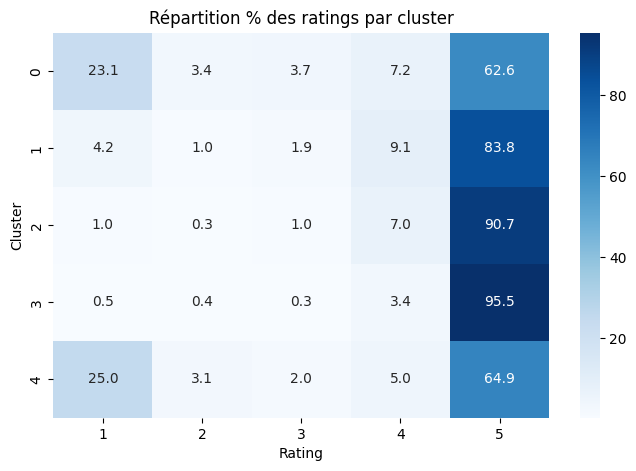

In [ ]:
df.groupby("cluster")["rating"].value_counts(normalize=True).mul(100).round(1)
import matplotlib.pyplot as plt
import seaborn as sns

# Table cluster × rating (%)
ct = (
    df.groupby("cluster")["rating"]
      .value_counts(normalize=True)
      .mul(100)
      .round(1)
      .unstack(fill_value=0)
      .sort_index()
)

# =============================
# 🔥 1) HEATMAP (très lisible)
# =============================
plt.figure(figsize=(8,5))
sns.heatmap(ct, annot=True, cmap="Blues", fmt=".1f")
plt.title("Répartition % des ratings par cluster")
plt.xlabel("Rating")
plt.ylabel("Cluster")
plt.show()

# =============================
# 🔥 2) BARPLOT EMPILÉ
# ==============



✔️ STRATÉGIE 2 — Cluster Hors données textuelles

In [ ]:
# ============================================================
# STRATÉGIE 1 : Clustering sur métadonnées (hors texte)
# ============================================================

# Réutiliser df chargé en cellule 0
# Si besoin de recharger :
# df = pd.read_csv("../data/processed/reviews_clean.csv")

# ============================================================
# 1) Création des variables NON TEXTUELLES
# ============================================================

df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month
df["day"] = df["datetime"].dt.day
df["weekday"] = df["datetime"].dt.weekday
df["hour"] = df["datetime"].dt.hour

df["text_clean"] = df["text_clean"].fillna("").astype(str)
df["nb_mots"] = df["text_clean"].apply(lambda x: len(x.split()))
# char_len existe déjà dans le dataset

features = df[[
    "year","month","day","weekday","hour",
    "source","product_slug","category",
    "nb_mots","char_len"
]]

# ============================================================
# 2) Encodage + Scaling
# ============================================================

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

num_cols = ["year","month","day","weekday","hour","nb_mots","char_len"]
cat_cols = ["source","product_slug","category"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

X_meta = preprocessor.fit_transform(features)

# ============================================================
# 3) Clustering SANS texte
# ============================================================

k = 5
kmeans_meta = KMeans(n_clusters=k, random_state=42, n_init=10)
df["cluster_meta"] = kmeans_meta.fit_predict(X_meta)

# ============================================================
# 4) WordClouds basés sur le texte (non utilisés pour le clustering)
# ============================================================

for c in range(k):
    subset = df[df["cluster_meta"] == c]["text_clean"]
    texte = " ".join(subset.tolist())

    wc = WordCloud(width=1000, height=400, background_color="white").generate(texte)

    plt.figure(figsize=(12,5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"WordCloud — Cluster {c} (basé sur les métadonnées)")
    plt.show()

# ============================================================
# 5) HEATMAP cluster_meta × rating (%)
# ============================================================

ct = (
    df.groupby("cluster_meta")["rating"]
      .value_counts(normalize=True)
      .mul(100)
      .round(1)
      .unstack(fill_value=0)
)

plt.figure(figsize=(10,6))
sns.heatmap(ct, annot=True, cmap="Blues", fmt=".1f")
plt.title("Répartition % des ratings par cluster (métadonnées)")
plt.xlabel("Rating")
plt.ylabel("Cluster_meta")
plt.show()

# ============================================================
# 6) DENDROGRAMME basé sur les centroïdes KMeans
# ============================================================

centers = kmeans_meta.cluster_centers_
linked = linkage(centers, method='ward')

plt.figure(figsize=(12,6))
dendrogram(linked,
           labels=[f"Cluster {i}" for i in range(k)],
           orientation='top',
           distance_sort='descending')
plt.title("Dendrogramme (Ward sur centroïdes KMeans – métadonnées)")
plt.show()

In [ ]:
# ============================================================
# ANALYSE TEMPORELLE : Série temporelle des ratings
# ============================================================

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Réutiliser df chargé précédemment
print("Données chargées :", df.shape)

# ============================================================
# 1) Préparation de la série temporelle
# ============================================================

df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
df_ts = df[["datetime", "rating"]].dropna()

# Index temporel
df_ts = df_ts.set_index("datetime").sort_index()

# Agrégation mensuelle
df_mensuel = df_ts.resample("M").mean()

print("\nForme après agrégation :", df_mensuel.shape)
df_mensuel.tail()

# ===== Filtre sur les 24 derniers mois =====
df_24m = df_mensuel.last("24M").copy()

# ============================================================
# 2) Visualisation sur 24 mois
# ============================================================

plt.figure(figsize=(12,5))
plt.plot(df_24m, marker="o")
plt.title("Série temporelle (moyenne mensuelle) – 24 derniers mois")
plt.ylabel("Rating moyen")
plt.grid(True)
plt.show()

# ============================================================
# 3) Lissage (MA – EWMA)
# ============================================================

df_24m["MA_3"] = df_24m["rating"].rolling(3).mean()
df_24m["MA_6"] = df_24m["rating"].rolling(6).mean()
df_24m["EWMA_03"] = df_24m["rating"].ewm(alpha=0.3).mean()

plt.figure(figsize=(12,6))
plt.plot(df_24m["rating"], label="Original")
plt.plot(df_24m["MA_3"], label="MA 3 mois", linewidth=2)
plt.plot(df_24m["MA_6"], label="MA 6 mois", linewidth=2)
plt.plot(df_24m["EWMA_03"], label="EWMA α=0.3", linewidth=2)
plt.legend()
plt.title("Lissages de la série (24 mois)")
plt.grid(True)
plt.show()

# ============================================================
# 4) Décomposition (tendance + saison + résidu)
# ============================================================

# Vérifier qu'on a assez de données (minimum 2 périodes complètes)
if len(df_24m) >= 24:
    result = seasonal_decompose(df_24m["rating"], model="additive", period=12)
    plt.rcParams.update({'figure.figsize': (12,8)})
    result.plot()
    plt.show()
else:
    print(f"⚠️ Pas assez de données pour la décomposition saisonnière ({len(df_24m)} mois)")

# ============================================================
# 5) Modèle SARIMA (série mensuelle) - optionnel
# ============================================================

if len(df_24m) >= 24:
    try:
        model = SARIMAX(df_24m["rating"],
                        order=(1,1,1),
                        seasonal_order=(1,1,1,12))
        fit = model.fit(disp=False)
        print(fit.summary())

        # Prévision sur 6 mois
        forecast = fit.forecast(6)

        plt.figure(figsize=(12,5))
        plt.plot(df_24m["rating"], label="Historique")
        plt.plot(forecast, marker="o", label="Prévision (6 mois)")
        plt.title("Prévision SARIMA – 6 mois")
        plt.legend()
        plt.grid(True)
        plt.show()
    except Exception as e:
        print(f"⚠️ Erreur SARIMA : {e}")
else:
    print("⚠️ Modèle SARIMA ignoré (données insuffisantes)")

In [ ]:
# ============================================================
# STRATÉGIE 2 : Clustering TF-IDF sur avis négatifs
# ============================================================

# Réutiliser df chargé précédemment
# Utiliser text_clean pour le TF-IDF (déjà nettoyé)

# 1️⃣ Filtrer les avis avec notes faibles (1 et 2)
df_neg = df[df['rating'].isin([1, 2])].copy()
print(f"📉 Nombre d'avis avec note 1 ou 2 : {df_neg.shape[0]}")

# 2️⃣ Préparer les données textuelles
text_data = df_neg['text_clean'].fillna("").astype(str)

# 3️⃣ Vectorisation TF-IDF (stopwords français)
from sklearn.feature_extraction.text import FRENCH_STOP_WORDS

tfidf = TfidfVectorizer(
    stop_words=list(FRENCH_STOP_WORDS),
    max_features=1000,
    min_df=2
)
X_tfidf = tfidf.fit_transform(text_data)

# 4️⃣ Clustering KMeans (5 clusters pour les avis négatifs)
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_tfidf)

# Ajouter les clusters au dataframe
df_neg['cluster'] = clusters

# 5️⃣ Résumé des clusters
print("\n📊 Répartition des avis par cluster :")
print(df_neg['cluster'].value_counts().sort_index())

# 6️⃣ WordCloud pour chaque cluster
for i in range(n_clusters):
    cluster_text = " ".join(df_neg[df_neg['cluster'] == i]['text_clean'].astype(str))
    
    if len(cluster_text.strip()) > 0:
        wordcloud = WordCloud(
            width=800, 
            height=400, 
            background_color='white', 
            colormap='Reds'
        ).generate(cluster_text)

        plt.figure(figsize=(10, 4))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')
        plt.title(f"☁️ Nuage de mots - Cluster {i} (avis négatifs)", fontsize=14)
        plt.show()
    else:
        print(f"⚠️ Cluster {i} : pas de texte disponible")

# 7️⃣ Échantillons par cluster
print("\n📝 Exemples d'avis par cluster :")
for i in range(n_clusters):
    print(f"\n===== CLUSTER {i} =====")
    sample = df_neg[df_neg['cluster'] == i]['review_text'].head(3)
    for j, txt in enumerate(sample):
        print(f"  {j+1}. {txt[:150]}...")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/tmp/ipython-input-1325022468.py:36: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  future_dates = pd.date_range(start=last_date + pd.offsets.MonthEnd(1), periods=future_steps, freq='M')
/tmp/ipython-input-1325022468.py:58: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


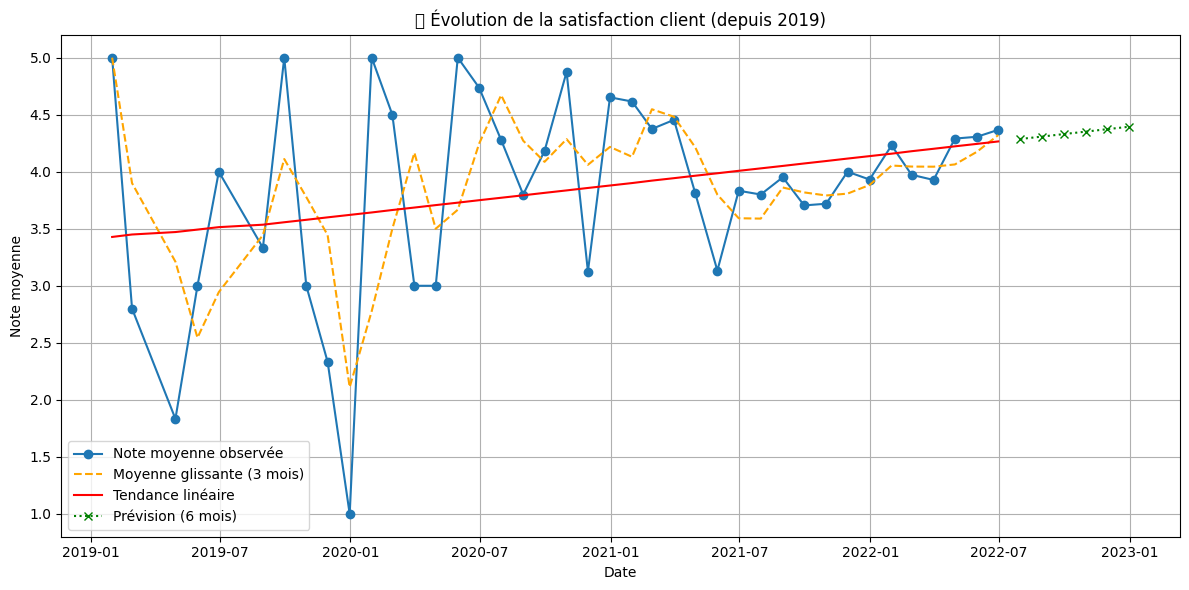

🔢 Intercept : 3.428
🔢 Pente mensuelle : 0.021
📆 Prévision pour les 6 mois à venir :
2022-07 → Note prévisionnelle : 4.29
2022-08 → Note prévisionnelle : 4.31
2022-09 → Note prévisionnelle : 4.33
2022-10 → Note prévisionnelle : 4.35
2022-11 → Note prévisionnelle : 4.37
2022-12 → Note prévisionnelle : 4.39


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 📅 1. Nettoyage des dates et des notes
df1['reviewed_at'] = pd.to_datetime(df1['reviewed_at'], errors='coerce')
df1 = df1.dropna(subset=['reviewed_at', 'rating'])

# ⏳ 2. Filtrer les données à partir de 2019
df_filtered = df1[df1['reviewed_at'] >= '2019-01-01'].copy()

# 📆 3. Agrégation mensuelle
df_ts = df_filtered.set_index('reviewed_at').resample('ME')['rating'].mean().reset_index()
df_ts = df_ts.dropna()  # Supprimer les mois vides

# 🔁 Moyenne glissante sur 3 mois
df_ts['rolling_mean'] = df_ts['rating'].rolling(window=3, min_periods=1).mean()

# ⏱ 4. Variable temps (index temporel)
df_ts['time_index'] = np.arange(len(df_ts))
X = df_ts[['time_index']]
y = df_ts['rating']

# 📈 5. Régression linéaire
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

# 📅 6. Prévision sur les 6 mois suivants
future_steps = 6
future_index = np.arange(len(df_ts), len(df_ts) + future_steps).reshape(-1, 1)
future_pred = model.predict(future_index)

last_date = df_ts['reviewed_at'].max()
future_dates = pd.date_range(start=last_date + pd.offsets.MonthEnd(1), periods=future_steps, freq='M')

# 📊 7. Affichage du graphique complet
plt.figure(figsize=(12, 6))

# Données observées
plt.plot(df_ts['reviewed_at'], df_ts['rating'], label='Note moyenne observée', marker='o')

# Moyenne glissante
plt.plot(df_ts['reviewed_at'], df_ts['rolling_mean'], label='Moyenne glissante (3 mois)', linestyle='--', color='orange')

# Tendance (régression)
plt.plot(df_ts['reviewed_at'], y_pred, label='Tendance linéaire', color='red')

# Prévision future
plt.plot(future_dates, future_pred, label='Prévision (6 mois)', linestyle=':', marker='x', color='green')

plt.title("📉 Évolution de la satisfaction client (depuis 2019)")
plt.xlabel("Date")
plt.ylabel("Note moyenne")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 📎 Résumé
print(f"🔢 Intercept : {model.intercept_:.3f}")
print(f"🔢 Pente mensuelle : {model.coef_[0]:.3f}")
print("📆 Prévision pour les 6 mois à venir :")
for date, pred in zip(future_dates, future_pred):
    print(f"{date.strftime('%Y-%m')} → Note prévisionnelle : {pred:.2f}")
